In [1]:
import pandas as pd

orders = pd.read_csv("../data/olist_orders_dataset.csv")
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [2]:
orders["order_delivered_customer_date"] = pd.to_datetime(orders["order_delivered_customer_date"])
orders["order_estimated_delivery_date"] = pd.to_datetime(orders["order_estimated_delivery_date"])

orders["delay_days"] = (orders["order_delivered_customer_date"] - orders["order_estimated_delivery_date"]).dt.days

orders[["order_id", "delay_days"]].head()

,order_id,delay_days
0,e481f51cbdc54678b7cc49136f2d6af7,-8.0
1,53cdb2fc8bc7dce0b6741e2150273451,-6.0
2,47770eb9100c2d0c44946d9cf07ec65d,-18.0
3,949d5b44dbf5de918fe9c16f97b45f8a,-13.0
4,ad21c59c0840e6cb83a9ceb5573f8159,-10.0


In [3]:
print("Total orders:", len(orders))
print("Missing delay_days:", orders["delay_days"].isna().sum())
print("Late orders (delay_days > 0):", (orders["delay_days"] > 0).sum())
orders["order_status"].value_counts()

Total orders: 99441
Missing delay_days: 2965
Late orders (delay_days > 0): 6535


order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

In [4]:
reviews = pd.read_csv("../data/olist_order_reviews_dataset.csv")
print(reviews.shape)
reviews[["order_id", "review_score"]].head()

(99224, 7)


,order_id,review_score
0,73fc7af87114b39712e6da79b0a377eb,4
1,a548910a1c6147796b98fdf73dbeba33,5
2,f9e4b658b201a9f2ecdecbb34bed034b,5
3,658677c97b385a9be170737859d3511b,5
4,8e6bfb81e283fa7e4f11123a3fb894f1,5


In [5]:
print(reviews["review_score"].value_counts().sort_index())
print("Unique order_id:", reviews["order_id"].nunique())
print("Duplicate order_id rows:", reviews["order_id"].duplicated().sum())

review_score
1    11424
2     3151
3     8179
4    19142
5    57328
Name: count, dtype: int64
Unique order_id: 98673
Duplicate order_id rows: 551


In [6]:
dups = reviews[reviews["order_id"].duplicated(keep=False)].sort_values("order_id")
dups[["order_id", "review_score", "review_creation_date"]].head(10)

,order_id,review_score,review_creation_date
25612,0035246a40f520710769010f752e7507,5,2017-08-29 00:00:00
22423,0035246a40f520710769010f752e7507,5,2017-08-25 00:00:00
22779,013056cfe49763c6f66bda03396c5ee3,5,2018-02-22 00:00:00
68633,013056cfe49763c6f66bda03396c5ee3,4,2018-03-04 00:00:00
854,0176a6846bcb3b0d3aa3116a9a768597,5,2017-12-30 00:00:00
83224,0176a6846bcb3b0d3aa3116a9a768597,5,2017-12-30 00:00:00
17582,02355020fd0a40a0d56df9f6ff060413,1,2018-03-29 00:00:00
89888,02355020fd0a40a0d56df9f6ff060413,3,2018-03-21 00:00:00
55137,029863af4b968de1e5d6a82782e662f5,4,2017-07-19 00:00:00
37911,029863af4b968de1e5d6a82782e662f5,5,2017-07-14 00:00:00


In [7]:
reviews["review_creation_date"] = pd.to_datetime(reviews["review_creation_date"])

reviews_clean = (
    reviews.sort_values("review_creation_date")
           .drop_duplicates(subset="order_id", keep="last")
)

print(reviews_clean.shape)
print("Duplicate order_id:", reviews_clean["order_id"].duplicated().sum())

(98673, 7)
Duplicate order_id: 0


In [8]:
delivered = orders[orders["order_status"] == "delivered"].copy()
delivered = delivered.dropna(subset=["delay_days"])

df = delivered.merge(
    reviews_clean[["order_id", "review_score"]],
    on="order_id",
    how="inner"
)

print("Delivered orders:", len(delivered))
print("After merge:", df.shape)
df[["order_id", "delay_days", "review_score"]].head()

Delivered orders: 96470
After merge: (95824, 10)


,order_id,delay_days,review_score
0,e481f51cbdc54678b7cc49136f2d6af7,-8.0,4
1,53cdb2fc8bc7dce0b6741e2150273451,-6.0,4
2,47770eb9100c2d0c44946d9cf07ec65d,-18.0,5
3,949d5b44dbf5de918fe9c16f97b45f8a,-13.0,5
4,ad21c59c0840e6cb83a9ceb5573f8159,-10.0,5


In [9]:
df["is_late"] = df["delay_days"] > 0

df.groupby("is_late")["review_score"].agg(["count", "mean", "median"])

,count,mean,median
is_late,,,
False,89443,4.290274,5.0
True,6381,2.270804,1.0


In [10]:
pd.crosstab(df["is_late"], df["review_score"], normalize="index").round(3) * 100

review_score,1,2,3,4,5
is_late,,,,,
False,6.6,2.6,8.1,20.4,62.3
True,53.8,8.6,10.9,10.2,16.5


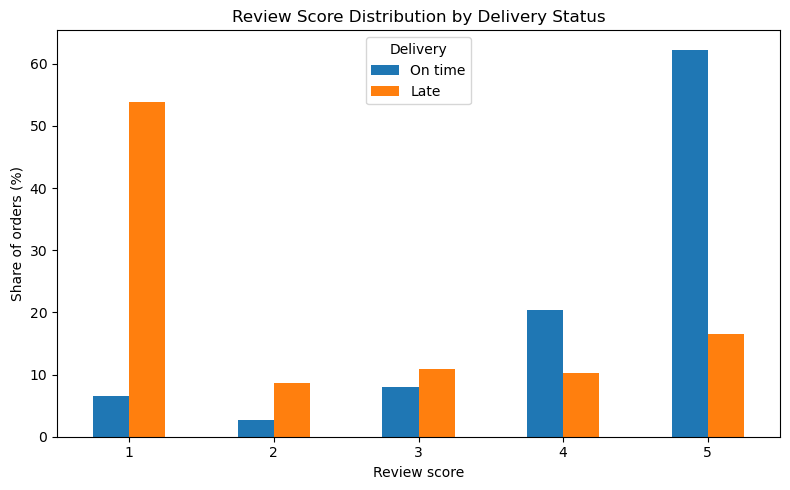

In [11]:
import matplotlib.pyplot as plt

dist = pd.crosstab(df["is_late"], df["review_score"], normalize="index") * 100
dist.index = ["On time", "Late"]

dist.T.plot(kind="bar", figsize=(8, 5))
plt.title("Review Score Distribution by Delivery Status")
plt.xlabel("Review score")
plt.ylabel("Share of orders (%)")
plt.xticks(rotation=0)
plt.legend(title="Delivery")
plt.tight_layout()
plt.savefig("../images/score_distribution.png", dpi=150)
plt.show()

In [12]:
from scipy.stats import mannwhitneyu

on_time = df.loc[~df["is_late"], "review_score"]
late = df.loc[df["is_late"], "review_score"]

stat, p = mannwhitneyu(late, on_time, alternative="two-sided")
print("U statistic:", stat)
print("p-value:", p)

U statistic: 103363826.0
p-value: 0.0


In [13]:
n_late = len(late)
n_on_time = len(on_time)

prob = stat / (n_late * n_on_time)
rank_biserial = 2 * prob - 1

print("Probability (late > on time):", round(prob, 3))
print("Rank-biserial correlation:", round(rank_biserial, 3))

Probability (late > on time): 0.181
Rank-biserial correlation: -0.638


In [14]:
late_df = df[df["delay_days"] > 0].copy()

late_df["delay_group"] = pd.cut(
    late_df["delay_days"],
    bins=[0, 3, 7, 14, float("inf")],
    labels=["1-3 days", "4-7 days", "8-14 days", "15+ days"]
)

late_df.groupby("delay_group", observed=True)["review_score"].agg(["count", "mean"])

,count,mean
delay_group,,
1-3 days,1852,3.291037
4-7 days,1748,2.104691
8-14 days,1446,1.670816
15+ days,1335,1.722846


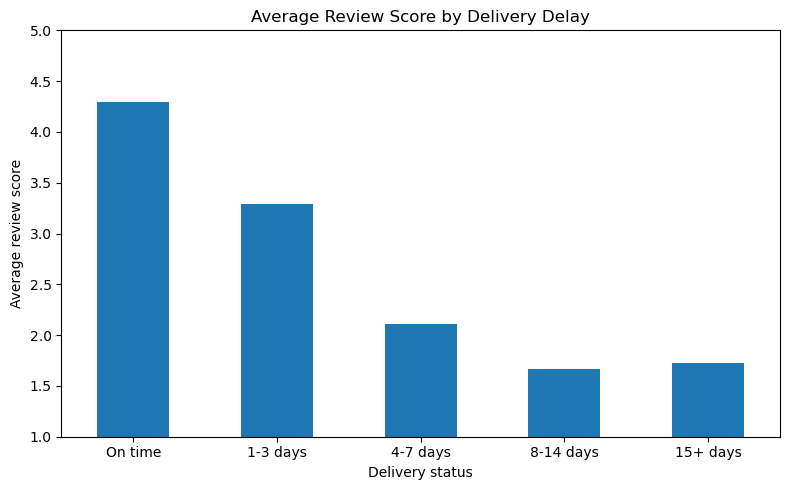

In [15]:
summary = late_df.groupby("delay_group", observed=True)["review_score"].mean()
on_time_mean = df.loc[~df["is_late"], "review_score"].mean()

summary = pd.concat([pd.Series({"On time": on_time_mean}), summary])

summary.plot(kind="bar", figsize=(8, 5))
plt.title("Average Review Score by Delivery Delay")
plt.xlabel("Delivery status")
plt.ylabel("Average review score")
plt.xticks(rotation=0)
plt.ylim(1, 5)
plt.tight_layout()
plt.savefig("../images/delay_vs_score.png", dpi=150)
plt.show()

In [16]:
customers = pd.read_csv("../data/olist_customers_dataset.csv")

df = df.merge(customers[["customer_id", "customer_state"]], on="customer_id", how="left")

by_state = df.groupby("customer_state").agg(
    orders=("order_id", "count"),
    late_rate=("is_late", "mean"),
    mean_score=("review_score", "mean")
).round(3)

by_state.sort_values("late_rate", ascending=False).head(10)

,orders,late_rate,mean_score
customer_state,,,
AL,394,0.208,3.848
MA,712,0.171,3.833
SE,334,0.150,3.907
PI,471,0.138,3.994
CE,1273,0.137,3.944
RR,41,0.122,3.902
BA,3229,0.119,3.930
RJ,12211,0.119,3.966
PA,933,0.107,3.914


In [17]:
top_states = by_state[by_state["orders"] >= 1000].index

within = (
    df[df["customer_state"].isin(top_states)]
    .pivot_table(index="customer_state", columns="is_late",
                 values="review_score", aggfunc="mean")
    .round(2)
)
within.columns = ["On time", "Late"]
within["Gap"] = (within["Late"] - within["On time"]).round(2)

within.sort_values("Gap")

,On time,Late,Gap
customer_state,,,
RJ,4.24,1.91,-2.33
DF,4.26,1.97,-2.29
PE,4.30,2.03,-2.27
CE,4.25,2.04,-2.21
RS,4.31,2.21,-2.10
GO,4.23,2.20,-2.03
SC,4.29,2.35,-1.94
MG,4.28,2.36,-1.92
BA,4.14,2.35,-1.79


In [18]:
items = pd.read_csv("../data/olist_order_items_dataset.csv")

sellers_per_order = items.groupby("order_id")["seller_id"].nunique()

print("Number of orders:", len(sellers_per_order))
print("Single-seller orders:", (sellers_per_order == 1).sum())
print("Multi-seller orders:", (sellers_per_order > 1).sum())

Number of orders: 98666
Single-seller orders: 97388
Multi-seller orders: 1278


In [19]:
single = sellers_per_order[sellers_per_order == 1].index

order_seller = (
    items[items["order_id"].isin(single)][["order_id", "seller_id"]]
    .drop_duplicates()
)

df_seller = df.merge(order_seller, on="order_id", how="inner")

print("Orders before merge:", len(df))
print("Orders with seller added:", len(df_seller))
print("Duplicate order_id:", df_seller["order_id"].duplicated().sum())
print("Distinct sellers:", df_seller["seller_id"].nunique())

Orders before merge: 95824
Orders with seller added: 94563
Duplicate order_id: 0
Distinct sellers: 2944


In [20]:
seller_stats = df_seller.groupby("seller_id").agg(
    orders=("order_id", "count"),
    late_orders=("is_late", "sum"),
    late_rate=("is_late", "mean"),
    mean_score=("review_score", "mean")
)

print(seller_stats["orders"].describe())
print("Sellers with at least 30 orders:", (seller_stats["orders"] >= 30).sum())
print("Sellers with no late orders:", (seller_stats["late_orders"] == 0).sum())

count    2944.000000
mean       32.120584
std       102.724844
min         1.000000
25%         2.000000
50%         7.000000
75%        22.000000
max      1774.000000
Name: orders, dtype: float64
Sellers with at least 30 orders: 614
Sellers with no late orders: 1690


In [21]:
big = seller_stats[seller_stats["orders"] >= 30].index
d = df_seller[df_seller["seller_id"].isin(big)]

g = d.groupby(["seller_id", "is_late"])["review_score"].agg(["count", "mean"]).unstack()
g.columns = ["n_on_time", "n_late", "mean_on_time", "mean_late"]

g = g[g["n_late"] >= 5].dropna()
g["gap"] = g["mean_late"] - g["mean_on_time"]

print("Sellers compared:", len(g))
print(g["gap"].describe())
print("Share of sellers with negative gap:", (g["gap"] < 0).mean().round(3))

Sellers compared: 285
count    285.000000
mean      -2.017548
std        0.590683
min       -3.581818
25%       -2.424242
50%       -2.008400
75%       -1.654762
max        0.016667
Name: gap, dtype: float64
Share of sellers with negative gap: 0.996


In [22]:
products = pd.read_csv("../data/olist_products_dataset.csv")
translation = pd.read_csv("../data/product_category_name_translation.csv")

items_cat = items.merge(
    products[["product_id", "product_category_name"]], on="product_id", how="left"
)
items_cat = items_cat.merge(translation, on="product_category_name", how="left")

cats_per_order = items_cat.groupby("order_id")["product_category_name_english"].nunique()

print("Orders with 1 category:", (cats_per_order == 1).sum())
print("Orders with more than 1 category:", (cats_per_order > 1).sum())
print("Orders with no category info:", (cats_per_order == 0).sum())

Orders with 1 category: 96530
Orders with more than 1 category: 726
Orders with no category info: 1410


In [23]:
missing = items_cat[items_cat["product_category_name_english"].isna()]

print("Items with missing English category:", len(missing))
print("...of which product_category_name is missing:", missing["product_category_name"].isna().sum())
print("...of which name exists but has no translation:", missing["product_category_name"].notna().sum())
print(missing["product_category_name"].value_counts().head())

Items with missing English category: 1627
...of which product_category_name is missing: 1603
...of which name exists but has no translation: 24
product_category_name
portateis_cozinha_e_preparadores_de_alimentos    15
pc_gamer                                          9
Name: count, dtype: int64


In [24]:
extra = pd.DataFrame({
    "product_category_name": ["portateis_cozinha_e_preparadores_de_alimentos", "pc_gamer"],
    "product_category_name_english": ["portable_kitchen_food_preparers", "pc_gamer"]
})
translation_fixed = pd.concat([translation, extra], ignore_index=True)

items_cat = items.merge(
    products[["product_id", "product_category_name"]], on="product_id", how="left"
)
items_cat = items_cat.merge(translation_fixed, on="product_category_name", how="left")

cats_per_order = items_cat.groupby("order_id")["product_category_name_english"].nunique()
single_cat = cats_per_order[cats_per_order == 1].index

order_cat = (
    items_cat[items_cat["order_id"].isin(single_cat)][["order_id", "product_category_name_english"]]
    .dropna()
    .drop_duplicates()
)
order_cat.columns = ["order_id", "category"]

df_cat = df.merge(order_cat, on="order_id", how="inner")

print("Orders before merge:", len(df))
print("Orders with category added:", len(df_cat))
print("Duplicate order_id:", df_cat["order_id"].duplicated().sum())
print("Distinct categories:", df_cat["category"].nunique())

Orders before merge: 95824
Orders with category added: 93781
Duplicate order_id: 0
Distinct categories: 73


In [25]:
c = df_cat.groupby(["category", "is_late"])["review_score"].agg(["count", "mean"]).unstack()
c.columns = ["n_on_time", "n_late", "mean_on_time", "mean_late"]

c = c[c["n_late"] >= 30].dropna()
c["gap"] = (c["mean_late"] - c["mean_on_time"]).round(2)

print("Categories compared:", len(c))
print(c["gap"].describe())
print("Share of categories with negative gap:", (c["gap"] < 0).mean().round(3))
c.sort_values("gap").head(5)

Categories compared: 28
count    28.000000
mean     -2.026786
std       0.223409
min      -2.520000
25%      -2.132500
50%      -2.055000
75%      -1.900000
max      -1.420000
Name: gap, dtype: float64
Share of categories with negative gap: 1.0


,n_on_time,n_late,mean_on_time,mean_late,gap
category,,,,,
musical_instruments,552.0,46.0,4.431159,1.913043,-2.52
audio,299.0,40.0,4.137124,1.725000,-2.41
toys,3493.0,230.0,4.387919,2.121739,-2.27
baby,2477.0,218.0,4.319742,2.073394,-2.25
sports_leisure,6933.0,485.0,4.384393,2.160825,-2.22
